## Deep Learning for Trading Signal Construction






## Getting started with neural networks

### Implementing Neural Networks in Keras

First, we import <b>Keras</b> (this requires that <b>TensorFlow</b> is installed):


In [38]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hides TensorFlow's start up log messages

import tensorflow as tf
import keras
from keras import layers

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


Second, for later use we import <b>NumPy</b> and <b>matplotlib</b> (and set a nicer plotting style).

In [39]:
import sys
sys.path.append('..')  # so we can import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8-whitegrid")

We now specify a feedforward neural network with, for example,  $L=3$, $d=N_0=2$, $N_1=100$, $N_2=100$, $N_3=1$, $\varrho_1(x)=\varrho_2(x)=\mathrm{ReLU}(x)=\max(x,0)$, $\varrho_3(x)=x$ as follows. A shorthand notation that we will use for such a network is
$$
f \in \mathcal{N}_3(2,100,100,1;\mathrm{ReLU},\mathrm{ReLU},\mathrm{Id}).
$$

Specifying such a neural network can be done using the <code>Sequential</code> model of Keras by:

In [40]:
# f: 2 inputs -> 100 ReLU -> 100 ReLU -> 1 linear output
f = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(100, activation="relu"),
    layers.Dense(100, activation="relu"),
    layers.Dense(1, activation="linear"),   # Id(x) = x, so the output is unbounded
])

An alternative, but equivalent, way of doing the same using the <code>add</code> method is:

In [41]:
# exactly the same network, built one layer at a time
g = keras.Sequential()
g.add(keras.Input(shape=(2,)))
g.add(layers.Dense(100, activation="relu"))
g.add(layers.Dense(100, activation="relu"))
g.add(layers.Dense(1, activation="linear"))

The <code>summary</code> method lets us summarise the specified architecture of the network $f$ and its parameters.

For each layer, the parameter is $N_{\textrm{output}}\times (N_{\textrm{input}}+1)$.


In [42]:
f.summary()
# check the parameter counts by hand with N_output x (N_input + 1):
# layer 1: 100 x (2 + 1) = 300, layer 2: 100 x (100 + 1) = 10,100, layer 3: 1 x (100 + 1) = 101
print("by hand:", 100 * 3 + 100 * 101 + 1 * 101)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 100)            │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,501 (41.02 KB)

 Trainable params: 10,501 (41.02 KB)

 Non-trainable params: 0 (0.00 B)

by hand: 10501


We can also visualise the architecture using the function <code>plot_model</code> in <code>keras.utils</code>. (Which is particularly helpful when we have built a model with complicated routings.)

In [43]:
# plot_model needs the pydot package and graphviz installed, so don't crash if they are missing
try:
    keras.utils.plot_model(f, show_shapes=True, to_file="f.png")
    from IPython.display import Image
    display(Image("f.png"))
except Exception as e:
    print("plot_model not available here:", type(e).__name__)

You must install pydot (`pip install pydot`) for `plot_model` to work.


FileNotFoundError: No such file or directory: 'f.png'

FileNotFoundError: No such file or directory: 'f.png'

<IPython.core.display.Image object>

We can remove the final layer of the network using the <code>pop</code> method:

In [44]:
f.pop()   # removes the last (output) layer

<Dense name=dense_21, built=True>

We should then get $f \in \mathcal{N}_2(2,100,100;\mathrm{ReLU},\mathrm{ReLU})$, which we can verify with the <code>summary</code> method.

In [45]:
f.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 100)            │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 100)            │        10,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,400 (40.62 KB)

 Trainable params: 10,400 (40.62 KB)

 Non-trainable params: 0 (0.00 B)

Let us however <code>add</code> the deleted layer back to the network $f$:

In [46]:
f.add(layers.Dense(1, activation="linear"))
f.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 100)            │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,501 (41.02 KB)

 Trainable params: 10,501 (41.02 KB)

 Non-trainable params: 0 (0.00 B)

We can study the layers of the network using the <code>get_layer</code> method. If we are, for example, interested in extracting the layer $\boldsymbol{L}_1(\boldsymbol{x}) = W^1\boldsymbol{x} + \boldsymbol{b}^1$, $\boldsymbol{x} \in \mathbb{R}^2$, we can do it as follows (remember that in Python indexation starts from zero):

In [47]:
L1 = f.get_layer(index=0)   # first Dense layer (the Input is not counted as a layer)
L1

<Dense name=dense_19, built=True>

We can inspect the weight matrix $W^1$ and bias vector $\boldsymbol{b}^1$ using the <code>get_weights</code> method.

In [48]:
W1, b1 = L1.get_weights()
# NOTE: Keras stores the weights as (inputs, outputs) = (2, 100), the transpose of the
# W^1 in the maths above, because it computes x @ W + b with x as a row vector
print(W1.shape, b1.shape)
print("biases all zero:", np.all(b1 == 0))

(2, 100) (100,)
biases all zero: True


We have not trained $f$ yet, so $W^1 \in \mathbb{R}^{100 \times 2}$ and $\boldsymbol{b}^1 \in \mathbb{R}^{100}$ are at their initialiser values. By default, <b>Keras</b> uses the random <i>Glorot</i> initialiser for weights and just zeros for biases.

We could also specify weights manually using the <code>set_weights</code> method. But it is recommended to use the default initialization.

The method <code>predict</code> lets us compute $f(\boldsymbol{x})$ for given input $\boldsymbol{x} \in \mathbb{R}^2$. The method expects here the input in the shape <code>(N,2)</code>, where <code>N</code> is the number of different values of $\boldsymbol{x}$ for which we want $f(\boldsymbol{x})$ to be computed.  

In [49]:
# predict wants shape (N, 2): here N = 3 different inputs
x = np.array([[0.0, 1.0],
              [0.5, 1.0],
              [-0.5, 1.0]])
f.predict(x, verbose=0)

array([[-0.15487802],
       [-0.24082686],
       [-0.10268775]], dtype=float32)

To gain some insight into what an untrained ReLU network looks like, let us use <code>predict</code> to plot $f(x,1)$ for $x \in [-1,1]$.

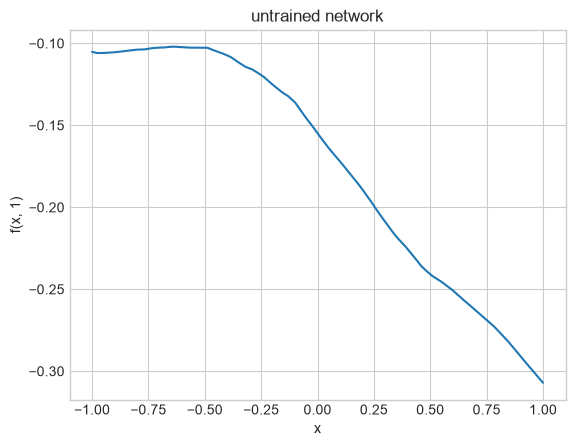

In [50]:
# f(x, 1) for x in [-1, 1]: an untrained ReLU network is just a random piecewise linear function
xs = np.linspace(-1, 1, 201)
inputs = np.column_stack([xs, np.ones_like(xs)])
plt.plot(xs, f.predict(inputs, verbose=0))
plt.xlabel("x")
plt.ylabel("f(x, 1)")
plt.title("untrained network")
plt.show()

To prepare $f$ for training, we can use the <code>compile</code> method to specify the loss function $\ell$ and the optimisation method.

For example, we can set $\ell$ to be squared loss to be optimised with <i>SGD</i> by:

In [51]:
f.compile(loss="mean_squared_error", optimizer=keras.optimizers.SGD(learning_rate=0.01))

We can also use the binary cross-entropy loss for binary classification.

In [52]:
# for classification. f has a LINEAR output, so it gives a raw score (a "logit"), not a probability.
# from_logits=True tells Keras to apply the sigmoid inside the loss. Later we put a sigmoid
# in the last layer instead, and then the default from_logits=False is the right choice.
f.compile(loss=keras.losses.BinaryCrossentropy(from_logits=True),
          optimizer=keras.optimizers.SGD(learning_rate=0.01),
          metrics=["accuracy"])

## Trading signal construction from limit order book data

We load the data as for the logistic regression.

In [53]:
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from src.data import load_lob
from src.features import add_lob_features

data_A = load_lob("Data_A")
data_B = load_lob("Data_B")

In [54]:
print(data_A.shape, data_B.shape)
print("share of up moves:", round(data_A["label"].mean(), 4))

(100000, 22) (10000, 22)
share of up moves: 0.5027


In [55]:
data_A.head()

,label,ask1_price,ask1_vol,bid1_price,bid1_vol,ask2_price,ask2_vol,bid2_price,bid2_vol,ask3_price,...,bid3_vol,ask4_price,ask4_vol,bid4_price,bid4_vol,prev_dir_1,prev_dir_2,prev_dir_3,prev_dir_4,prev_dir_5
0,1,428900.0,1,428700.0,200,429000.0,100,428500.0,300,429100.0,...,300,429200.0,200,428300.0,100,0,1,0,1,0
1,1,427100.0,100,427000.0,100,427200.0,940,426900.0,100,427300.0,...,100,427400.0,700,426700.0,100,0,1,0,1,0
2,1,511300.0,100,511200.0,129,511400.0,500,511100.0,200,511500.0,...,300,511600.0,200,510900.0,300,0,1,1,0,0
3,0,415600.0,200,415400.0,100,415700.0,100,415300.0,100,415800.0,...,600,415900.0,300,415100.0,1020,0,1,1,0,1
4,0,506600.0,300,506500.0,100,506700.0,100,506300.0,200,506800.0,...,1099,506900.0,214,506100.0,699,0,0,1,1,0


Split the data into features and labels. We also set aside part of the data for validating.

In [56]:
# exactly the same split as notebook 03 (first 80,000 rows train, last 20,000 validate)
X = data_A.drop(columns="label").values
y = data_A["label"].values
SPLIT = 80_000
X_train, X_val = X[:SPLIT], X[SPLIT:]
y_train, y_val = y[:SPLIT], y[SPLIT:]

X_test = data_B.drop(columns="label").values
y_test = data_B["label"].values

Normalize the features to similar scales.

In [57]:
scaler = StandardScaler().fit(X_train)   # training data only
X_train_s, X_val_s, X_test_s = (scaler.transform(A) for A in (X_train, X_val, X_test))

We are now ready to build and train our first deep neural network.

For illustration purposes we fix the random seed here. What happens when we don't?



In [58]:
# fixes the seed for python, numpy and tensorflow in one go
# without it every run starts from different random weights (and shuffles differently),
# so the accuracies wobble a little from run to run
keras.utils.set_random_seed(125)   # same seed as the lecture

We start with a first baseline model.

Note that the activation function of the output layer is **sigmoid**. This ensures the output takes values in $[0,1]$.

In [59]:
def build_model(lr, dropout=0.0, n_inputs=X_train_s.shape[1]):
    """Same network as the lecture: 100 then 200 ReLU units, optional dropout,
    sigmoid output = probability of an up move."""
    model = keras.Sequential([keras.Input(shape=(n_inputs,))])
    for units in (100, 200):
        model.add(layers.Dense(units, activation="relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(loss="binary_crossentropy",
                  optimizer=keras.optimizers.Adam(learning_rate=lr),
                  metrics=["accuracy"])
    return model

# baseline: deliberately large learning rate
model_1 = build_model(lr=0.1)

In [ ]:
history_1 = model_1.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                        epochs=40, batch_size=128, verbose=0)
print(f"final validation accuracy: {history_1.history['val_accuracy'][-1]:.4f}")

Next we introduce a customized plotting function to visually examine how training has progressed.

In [ ]:
def plot_history(history, title=""):
    """Loss and accuracy per epoch, training vs validation, side by side."""
    h = history.history
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
    ax1.plot(h["loss"], label="train")
    ax1.plot(h["val_loss"], label="validation")
    ax1.set_title("loss")
    ax2.plot(h["accuracy"], label="train")
    ax2.plot(h["val_accuracy"], label="validation")
    ax2.set_title("accuracy")
    for ax in (ax1, ax2):
        ax.set_xlabel("epoch")
        ax.legend()
    fig.suptitle(title)
    plt.show()

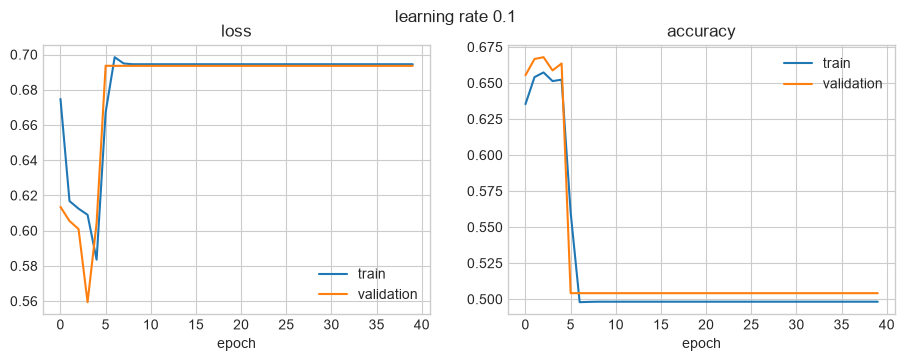

In [ ]:
plot_history(history_1, "learning rate 0.1")

#### Question: Have a look at the plots visualizing the training process. What do you observe? How could you resolve it?

_____

**My answer:** the curves jump around from epoch to epoch and the validation accuracy never settles. Each update step is too big, so the weights keep overshooting the minimum. The fix is a smaller learning rate.

The training process is still very noisy. This indicates that the learning rate that we are using is probably too high.   First let us decrease the learning rate. Intuitively, this means that we may need to train longer, but that the training process is more sensitive and thus potentially we may find a better local minimum.

In [ ]:
keras.utils.set_random_seed(125)
model_2 = build_model(lr=0.001)

In [ ]:
history_2 = model_2.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                        epochs=40, batch_size=128, verbose=0)
print(f"validation accuracy: lr 0.1 -> {history_1.history['val_accuracy'][-1]:.4f}, "
      f"lr 0.001 -> {history_2.history['val_accuracy'][-1]:.4f}")

validation accuracy: lr 0.1 -> 0.5041, lr 0.001 -> 0.7628


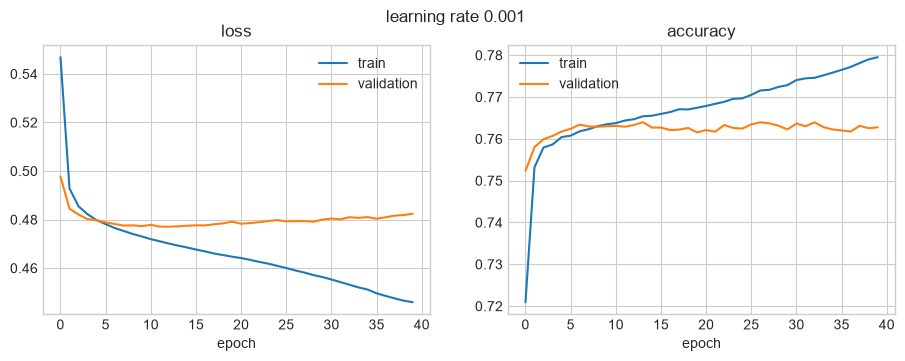

In [ ]:
plot_history(history_2, "learning rate 0.001")

We see that the appropriate choice of learning rate has allowed us to stablize the learning process and also significantly improve the validation accuracy.

####  Have a look at the new plots of the training process. What do you observe?
____

**My answer:** the training loss keeps falling, but after a while the validation loss stops falling and starts creeping back up, while training accuracy pulls away from validation accuracy. The network has started memorising the training rows instead of learning patterns that generalise: overfitting.

From the graph we see that after a while we started to overfit! There are two things we can do against this:

- Introduce a dropout layer
- Stop training earlier


Let us try the first option and see if we are able to improve the validation accuracy even further.

In [ ]:
keras.utils.set_random_seed(125)
model_3 = build_model(lr=0.001, dropout=0.2)
# dropout randomly switches off 20% of the hidden units at each training step,
# so the network cannot rely on any single unit; it is switched off automatically when predicting

Visualize the network with dropout layers

In [ ]:
model_3.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                │ (None, 100)            │         2,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 200)            │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │           201 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,601 (88.29 KB)

 Trainable params: 22,601 (88.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_3 = model_3.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                        epochs=40, batch_size=128, verbose=0)

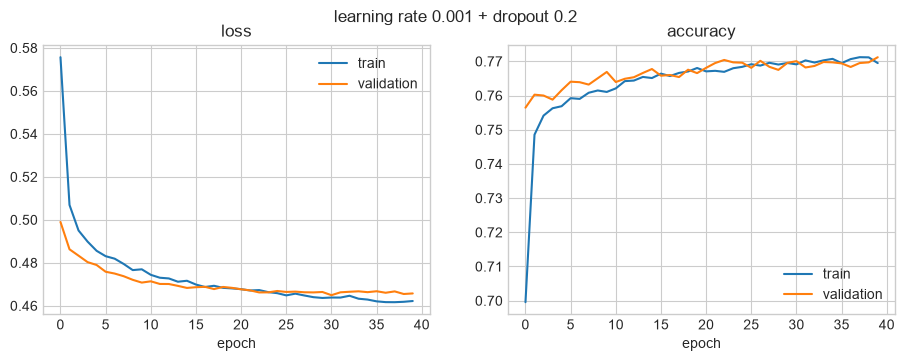

In [ ]:
plot_history(history_3, "learning rate 0.001 + dropout 0.2")

In [ ]:
for name, h in [("lr 0.1", history_1), ("lr 0.001", history_2), ("lr 0.001 + dropout", history_3)]:
    print(f"{name:20s} best validation accuracy {max(h.history['val_accuracy']):.4f}, "
          f"final {h.history['val_accuracy'][-1]:.4f}")

lr 0.1               best validation accuracy 0.6679, final 0.5041
lr 0.001             best validation accuracy 0.7640, final 0.7628
lr 0.001 + dropout   best validation accuracy 0.7712, final 0.7712


We see that we have been able to further improve the validation accuracy. Most of the overfitting has been mitigated.

#### Challenge: can you further improve the validation accuracy?

Possible points you may try:

- Features (use only a selection)
- Learning rate
- Activation function
- Number of layers
- Dropout layers
- Batch normalization layers

**My attempt.** Two changes, judged on the validation set only:

1. **Better inputs.** The order book features from notebook 03 (spread, imbalance, gaps between levels), see `add_lob_features` in `src/features.py`.
2. **Stop at the right time.** Early stopping watches the validation loss and keeps the weights from the best epoch, instead of me guessing the number of epochs.

stopped after 43 epochs, best validation accuracy 0.7711


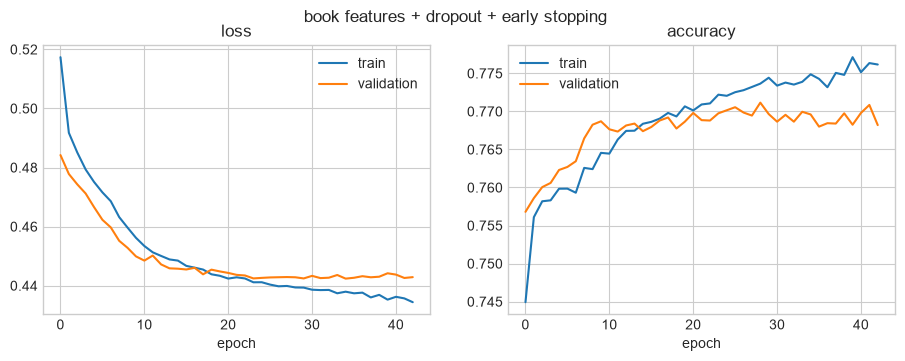

In [ ]:
feat_A = add_lob_features(data_A)
feat_B = add_lob_features(data_B)

XE = feat_A.drop(columns="label").values
XE_train, XE_val = XE[:SPLIT], XE[SPLIT:]
XE_test = feat_B.drop(columns="label").values

scaler_E = StandardScaler().fit(XE_train)
XE_train_s, XE_val_s, XE_test_s = (scaler_E.transform(A) for A in (XE_train, XE_val, XE_test))

keras.utils.set_random_seed(125)
model_4 = build_model(lr=0.001, dropout=0.2, n_inputs=XE_train_s.shape[1])
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

history_4 = model_4.fit(XE_train_s, y_train, validation_data=(XE_val_s, y_val),
                        epochs=100, batch_size=128, verbose=0, callbacks=[early_stop])
print(f"stopped after {len(history_4.history['loss'])} epochs, "
      f"best validation accuracy {max(history_4.history['val_accuracy']):.4f}")
plot_history(history_4, "book features + dropout + early stopping")





Finally we now assess the out-of-sample performance of your network.

In [ ]:
# out of sample on Data_B, only now, once the models are fixed
test_acc = {
    "network, lr 0.1": model_1.evaluate(X_test_s, y_test, verbose=0)[1],
    "network, lr 0.001": model_2.evaluate(X_test_s, y_test, verbose=0)[1],
    "network, lr 0.001 + dropout": model_3.evaluate(X_test_s, y_test, verbose=0)[1],
    "network, + book features + early stopping": model_4.evaluate(XE_test_s, y_test, verbose=0)[1],
}

In [ ]:
for name, acc in test_acc.items():
    print(f"Test accuracy of {name}: {acc:.4f}")

Test accuracy of network, lr 0.1: 0.4883
Test accuracy of network, lr 0.001: 0.7675
Test accuracy of network, lr 0.001 + dropout: 0.7713
Test accuracy of network, + book features + early stopping: 0.7751


For comparison, the logistic regression models from notebook 03. I refit them here on exactly the same split so the numbers line up.

In [ ]:
logit = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
logit_sq = make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
                         LogisticRegression(solver="newton-cg", max_iter=1000)).fit(X_train_s, y_train)

comparison = pd.Series({
    "logistic, linear": logit.score(X_test_s, y_test),
    "logistic, degree 2": logit_sq.score(X_test_s, y_test),
    **test_acc,
})
comparison.round(4).to_frame("test accuracy (Data_B)")

,test accuracy (Data_B)
"logistic, linear",0.7169
"logistic, degree 2",0.7339
"network, lr 0.1",0.4883
"network, lr 0.001",0.7675
"network, lr 0.001 + dropout",0.7713
"network, + book features + early stopping",0.7751
